# 02 - Baseline: TF-IDF + Logistic Regression

| Step | Details |
|---|---|
| Validation | fixed split from `common.split_train_val` |
| Features | TF-IDF word 1-2 / char_wb 2-5 n-grams |
| Model | LogisticRegression, grid over `C` by macro-F1 |
| Outputs | per-class report, confusion matrix, `submission_baseline.csv`, probabilities in `outputs/` |

- Vectorizers are fitted **on the train part only** (no leakage)
- Shared code: `src/common.py`

## Setup

In [1]:
import subprocess
import sys

REPO = "https://github.com/mohinska/ai_hw3_AIGenTextDetection.git"
REPO_DIR = "/tmp/repo"

subprocess.run(["rm", "-rf", REPO_DIR], check=True)
subprocess.run(["git", "clone", "-q", "--depth", "1", REPO, REPO_DIR], check=True)
sys.path.insert(0, f"{REPO_DIR}/src")

In [2]:
import os
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, f1_score

import common
from common import LABELS, TEXT_COL, LABEL_COL, SEED
from features import TFIDF, fit_tfidf, tfidf_transform

warnings.filterwarnings("ignore", category=UserWarning)

## Config

In [3]:
FINAL = False            # True: final run - whole train part, only the best config (char_wb_2-5, C=2)
N_TRAIN = None if FINAL else 60_000   # stratified subsample of the train part used for fitting
NAME = "baseline_full" if FINAL else "baseline"   # name of the saved probabilities / submission
REFIT_ON_TRAIN_PLUS_VAL = False  # True: refit best config on train+val before predicting test

OUT_DIR = os.path.join(common.WORK_DIR, "outputs")
SUBMISSION_PATH = os.path.join(common.WORK_DIR, f"submission_{NAME}.csv")
os.makedirs(OUT_DIR, exist_ok=True)

## Load data

In [4]:
train_df, test_df, sample_sub = common.load_data()
LANG_COL = common.lang_col(train_df)

assert set(train_df[LABEL_COL].unique()) == set(LABELS), train_df[LABEL_COL].unique()
print("train:", train_df.shape, "| test:", test_df.shape, "| columns:", list(train_df.columns))
train_df[LABEL_COL].value_counts(normalize=True).round(3)

train: (272352, 5) | test: (25000, 4) | columns: ['id', 'text', 'lang', 'domain', 'label']


label
ai        0.448
fusion    0.307
human     0.245
Name: proportion, dtype: float64

## Fixed validation split

| Parameter | Value |
|---|---|
| Size | 10% of train.csv |
| Stratified by | label + language |
| Seed | 42 |


In [5]:
trn, val = common.split_train_val(train_df)
val[["id"]].to_csv(os.path.join(OUT_DIR, f"val_ids_seed{SEED}.csv"), index=False)
trn = common.subsample(trn, N_TRAIN)
print(f"train part: {len(trn):,} | val: {len(val):,}")

train part: 60,000 | val: 27,236


In [6]:
def prep(texts):
    return texts.fillna("").astype(str)

X_trn_txt, y_trn = prep(trn[TEXT_COL]), trn[LABEL_COL].values
X_val_txt, y_val = prep(val[TEXT_COL]), val[LABEL_COL].values
X_test_txt = prep(test_df[TEXT_COL])

## Parameter search

- Each vectorizer is fitted once on the train part; validation is only transformed
- Feature sets: word, char, word+char
- Grid: `C` in `C_GRID`, metric: macro-F1

In [7]:
C_GRID = [2.0] if FINAL else [0.5, 2.0, 8.0]


fit_vectorizers, transform = fit_tfidf, tfidf_transform   # src/features.py (shared with 04 / 06)


def make_clf(C):
    return LogisticRegression(C=C, max_iter=2000, random_state=SEED)


feature_sets = {"word_1-2": ["word_1-2"],
                "char_wb_2-5": ["char_wb_2-5"],
                "word+char": ["word_1-2", "char_wb_2-5"]}
if FINAL:
    feature_sets = {"char_wb_2-5": ["char_wb_2-5"]}

fitted = fit_vectorizers({n for names in feature_sets.values() for n in names}, X_trn_txt)   # train part only
results = []
for fs_name, vec_names in feature_sets.items():
    vecs = {n: fitted[n] for n in vec_names}
    Xtr, Xva = transform(vecs, X_trn_txt), transform(vecs, X_val_txt)
    for C in C_GRID:
        t0 = time.time()
        clf = make_clf(C).fit(Xtr, y_trn)
        f1 = f1_score(y_val, clf.predict(Xva), average="macro")
        results.append({"features": fs_name, "C": C, "n_feats": Xtr.shape[1],
                        "macro_f1": round(f1, 4), "fit_s": round(time.time() - t0, 1)})

results_df = pd.DataFrame(results).sort_values("macro_f1", ascending=False).reset_index(drop=True)
results_df.to_csv(os.path.join(OUT_DIR, "baseline_grid.csv"), index=False)
results_df

,features,C,n_feats,macro_f1,fit_s
0,char_wb_2-5,2.0,300000,0.8724,279.4
1,word+char,2.0,600000,0.8723,374.8
2,word+char,8.0,600000,0.8721,469.6
3,char_wb_2-5,8.0,300000,0.8685,317.9
4,word+char,0.5,600000,0.8670,317.3
5,char_wb_2-5,0.5,300000,0.8615,290.3
6,word_1-2,8.0,300000,0.8467,98.2
7,word_1-2,2.0,300000,0.8455,94.0
8,word_1-2,0.5,300000,0.8362,97.8


## Best model on the validation split

In [8]:
best = results_df.iloc[0]
best_vecs = {n: fitted[n] for n in feature_sets[best["features"]]}
Xtr, Xva = transform(best_vecs, X_trn_txt), transform(best_vecs, X_val_txt)
best_clf = make_clf(best["C"]).fit(Xtr, y_trn)

val_proba = best_clf.predict_proba(Xva)
val_pred = best_clf.classes_[val_proba.argmax(1)]
print(f"best: {best['features']}, C={best['C']} -> val macro-F1 = {f1_score(y_val, val_pred, average='macro'):.4f}\n")
print(classification_report(y_val, val_pred, labels=LABELS, digits=4))

best: char_wb_2-5, C=2.0 -> val macro-F1 = 0.8724

              precision    recall  f1-score   support

       human     0.7816    0.8388    0.8092      6673
          ai     0.9785    0.9902    0.9843     12195
      fusion     0.8575    0.7927    0.8238      8368

    accuracy                         0.8924     27236
   macro avg     0.8726    0.8739    0.8724     27236
weighted avg     0.8931    0.8924    0.8921     27236



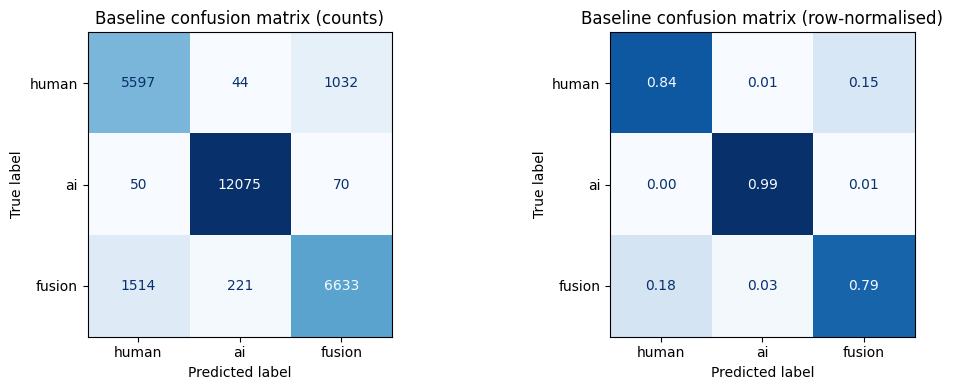

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, norm, title in zip(axes, [None, "true"], ["counts", "row-normalised"]):
    ConfusionMatrixDisplay.from_predictions(y_val, val_pred, labels=LABELS, normalize=norm,
                                            values_format=".2f" if norm else "d",
                                            cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(f"Baseline confusion matrix ({title})")
common.save_fig("baseline_cm.png")

In [10]:
# macro-F1 per language and per domain: where the model is weak
for col in [LANG_COL, "domain"]:
    if col in val.columns:
        display(common.f1_by(y_val, val_pred, val[col]))

,n,macro_f1
g,,
en-EN,21959,0.8664
de-DE,5277,0.8945


,n,macro_f1
g,,
blog_authorship_corpus,4022,0.7518
gutenberg,778,0.8025
arxiv_papers,1428,0.8511
house_of_commons,3229,0.8569
bundestag,5229,0.8948
student_essays,5433,0.8958
euro_court_cases,2757,0.9031
cnn_news,4360,0.9048


In [11]:
# Save validation probabilities: reused later for ensembling / threshold tuning
common.save_proba(val["id"], val_proba, best_clf.classes_, NAME, "val")

## Predict test and write submission

In [12]:
if REFIT_ON_TRAIN_PLUS_VAL:
    full_txt = pd.concat([X_trn_txt, X_val_txt], ignore_index=True)
    full_y = np.concatenate([y_trn, y_val])
    final_vecs = fit_vectorizers(feature_sets[best["features"]], full_txt)
    final_clf = make_clf(best["C"]).fit(transform(final_vecs, full_txt), full_y)
else:
    final_vecs, final_clf = best_vecs, best_clf

test_proba = final_clf.predict_proba(transform(final_vecs, X_test_txt))
test_pred = final_clf.classes_[test_proba.argmax(1)]

common.save_proba(test_df["id"], test_proba, final_clf.classes_, NAME, "test")

submission = common.save_submission(test_df["id"], test_pred, sample_sub, SUBMISSION_PATH)
print("saved", SUBMISSION_PATH, submission.shape)
submission["label"].value_counts(normalize=True).round(3)

saved /kaggle/working/submission_baseline.csv (25000, 2)


label
ai        0.518
human     0.262
fusion    0.220
Name: proportion, dtype: float64

## Conclusions

- **Best config:** `char_wb_2-5`, `C=2` -> val macro-F1 0.8724 (`word+char` 0.8723, `word_1-2` 0.8467). Char n-grams carry the signal -> reference for `04` / `06`
- **LB vs val:** public LB 0.86898 vs val 0.8724, scores are close so fixed split is reliable
- **Per class:** `ai` 0.984, `fusion` 0.824, `human` 0.809 -> `ai` is solved, `human` vs `fusion` is the hard part
- **Fusion under-predicted:** recall 0.79 vs 0.84 for `human` -> try class weights / scaling (`04`, `05`)
- **Weak domains:** `blog_authorship_corpus` 0.75, `gutenberg` 0.80; `gutenberg` is 3x larger in test
- **Languages:** `en` 0.866 vs `de` 0.895
- **Test predictions:** `ai` 51.8% vs 44.8% in train -> partly explained by more ai-heavy domains in test (`gutenberg` 7.4%, `arxiv_papers` 6.7%)